# Phase 2 — feature-augmented, selective reversal

See `STRATEGY.md` for the full 6-phase plan. Phase 1 (`momentum_reversal_baseline.ipynb`) found
a real but economically fragile reversal effect: trailing 1-minute return predicts forward
1-minute return with IC = -0.041 (pooled across 131 tickers, 1 month), and a corrected
long-short decile backtest showed +1.76bps gross per decision — which flips negative at just
1bps of assumed round-trip cost. The conclusion there was that trading the signal on *every*
minute's cross-section isn't viable; this notebook asks whether being **selective** (trading
only when additional context suggests the setup is "real") recovers enough edge to survive costs.

Originally three (a fourth, Garman-Klass realized volatility, was added later — see the
addendum near the end — bringing the total to four), all computed from the same 1-minute OHLCV
data already cached — no new data pull needed:

- **VWAP distance** — `close / session_vwap - 1`, where `session_vwap` is the cumulative
  volume-weighted average price from the session open through the current bar. Intuition: a
  reversal is more likely to be a genuine snap-back when price has drifted unusually far from
  where the session's volume has actually traded.
- **Volume surprise** — current bar's volume relative to this ticker's own typical volume at
  that same minute-of-session (intraday volume is strongly U-shaped, so "high volume" must be
  judged relative to time-of-day, not an all-day average).
- **Relative strength** — the trailing-1-minute return expressed as a cross-sectional z-score
  against all other tickers at that exact minute, rather than compared only to the stock's own
  history. This is the rotation strategy's own signal, demoted from primary driver to one input
  among several — exactly as the pasted research plan suggested.

**Method, deliberately unbiased about direction**: bucket observations by each feature's
magnitude and re-measure the reversal signal's IC within each bucket, looking for where it's
strongest — rather than assuming "high volume surprise = better" going in. Phase 1's backtest
direction bug (assuming momentum when the data said reversal) is the reason for this discipline:
let the buckets show which end is which, don't decide first.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = Path('data') / 'minute'
K, H = 1, 1   # Phase 1's strongest cell — this notebook conditions that specific signal, not the full k/h grid
N_BUCKETS = 3
COST_BPS_GRID = [0, 1, 2, 5, 10]
TOP_FRACTION = 0.1
GK_WINDOW_MINUTES = 10   # trailing window for the Garman-Klass realized-vol aggregation —
                         # a single 1-minute bar's GK estimate alone is too noisy to use directly

## Load bars and build features

Everything computed within-session (grouped by `session_date`) so nothing crosses an overnight gap, same discipline as Phase 1.

In [2]:
def load_ticker(ticker):
    frame = pd.read_csv(DATA_DIR / f'{ticker}.csv', parse_dates=['date'])
    frame['date'] = pd.to_datetime(frame['date'], utc=True)
    frame = frame.sort_values('date').set_index('date')
    frame['session_date'] = frame.index.tz_convert('America/New_York').date
    frame['minute_of_session'] = frame.groupby('session_date').cumcount()
    return frame

tickers = sorted(p.stem for p in DATA_DIR.glob('*.csv'))

frames = []
for ticker in tickers:
    df = load_ticker(ticker)
    g = df.groupby('session_date')

    trail = g['close'].transform(lambda s: s / s.shift(K) - 1)
    fwd = g['close'].transform(lambda s: s.shift(-H) / s - 1)
    reversal_score = -trail  # oriented so HIGHER score = higher predicted forward return, per Phase 1's finding (IC<0)

    # Session VWAP: cumulative volume-weighted average price from the open through this bar,
    # using IBKR's own per-bar 'average' (already volume-weighted within that single bar).
    pv = df['average'] * df['volume']
    cum_pv = pv.groupby(df['session_date']).cumsum()
    cum_vol = df['volume'].groupby(df['session_date']).cumsum()
    vwap_dist = df['close'] / (cum_pv / cum_vol) - 1

    # Volume surprise vs. this ticker's own full-sample average volume at that minute-of-session.
    # NOTE: uses the full one-month sample as the baseline, which means an early session in the
    # month is implicitly compared against volume from later in the month too — a mild look-ahead
    # that's fine for this diagnostic but would need a trailing/expanding baseline before any
    # live use (see caveats).
    baseline_vol = df.groupby('minute_of_session')['volume'].transform('mean')
    volume_surprise = df['volume'] / baseline_vol - 1

    # Garman-Klass (1980) per-bar variance estimator, using each bar's own OHLC range — more
    # statistically efficient than squared close-to-close returns since it also uses the
    # high/low spread within the bar, not just the open/close:
    #   GK_var = 0.5*(ln(H/L))^2 - (2*ln(2) - 1)*(ln(C/O))^2
    # A single 1-minute bar's estimate is extremely noisy on its own, so this is aggregated as a
    # trailing mean over GK_WINDOW_MINUTES (within session, never crossing into the prior day)
    # before being used as a feature — a short-horizon, session-local realized-vol estimate.
    # Occasional negative single-bar estimates (a known property of GK — the two terms can
    # partially cancel) are handled by clipping the *window-averaged* variance at zero before
    # the square root, not by clipping each bar individually.
    log_hl = np.log(df['high'] / df['low'])
    log_co = np.log(df['close'] / df['open'])
    gk_var_bar = 0.5 * log_hl ** 2 - (2 * np.log(2) - 1) * log_co ** 2
    gk_var_rolling = gk_var_bar.groupby(df['session_date']).transform(
        lambda s: s.rolling(GK_WINDOW_MINUTES, min_periods=GK_WINDOW_MINUTES).mean()
    )
    garman_klass_vol = np.sqrt(gk_var_rolling.clip(lower=0))

    frames.append(pd.DataFrame({
        'ticker': ticker, 'trail': trail, 'fwd': fwd, 'reversal_score': reversal_score,
        'vwap_dist': vwap_dist, 'volume_surprise': volume_surprise, 'garman_klass_vol': garman_klass_vol,
    }, index=df.index))

panel = pd.concat(frames).dropna(subset=['reversal_score', 'fwd', 'vwap_dist', 'volume_surprise', 'garman_klass_vol'])

# Relative strength: cross-sectional z-score of the trailing return at each exact minute, across
# whichever tickers have a valid observation at that instant.
cs_mean = panel.groupby(panel.index)['trail'].transform('mean')
cs_std = panel.groupby(panel.index)['trail'].transform('std')
panel['relative_strength'] = (panel['trail'] - cs_mean) / cs_std
panel = panel.dropna(subset=['relative_strength'])

print(f'{len(tickers)} tickers, {len(panel):,} (ticker, minute) observations with all features present')
baseline_ic = panel['reversal_score'].corr(panel['fwd'])
print(f'unconditional IC at k={K}, h={H}: {baseline_ic:+.4f} (should match Phase 1 magnitude, sign-flipped by construction)')

131 tickers, 1,066,891 (ticker, minute) observations with all features present
unconditional IC at k=1, h=1: +0.0482 (should match Phase 1 magnitude, sign-flipped by construction)


## Conditional IC — does each feature's magnitude select for a stronger reversal?

A fourth feature, Garman-Klass realized volatility, is included below too — see the feature-construction cell for its formula. Bucket by the **magnitude** (`abs()`) of each feature into terciles, since the hypothesis for all four is "more extreme = more informative," not a one-directional level effect.

In [3]:
FEATURES = ['vwap_dist', 'volume_surprise', 'relative_strength', 'garman_klass_vol']
bucket_rows = []
for feat in FEATURES:
    buckets = pd.qcut(panel[feat].abs(), N_BUCKETS, labels=['low', 'mid', 'high'], duplicates='drop')
    for label, group in panel.groupby(buckets, observed=True):
        bucket_rows.append({
            'feature': feat, 'bucket': label, 'n': len(group),
            'ic': group['reversal_score'].corr(group['fwd']),
        })
bucket_table = pd.DataFrame(bucket_rows)
display(bucket_table.pivot(index='feature', columns='bucket', values='ic')[['low', 'mid', 'high']].round(4))
display(bucket_table.pivot(index='feature', columns='bucket', values='n')[['low', 'mid', 'high']])

bucket,low,mid,high
feature,,,
garman_klass_vol,0.0500,0.0423,0.0496
relative_strength,-0.0202,0.0103,0.0763
volume_surprise,0.0415,0.0522,0.0508
vwap_dist,0.0387,0.0503,0.0522


bucket,low,mid,high
feature,,,
garman_klass_vol,355631,355630,355630
relative_strength,355630,355630,355631
volume_surprise,355631,355629,355631
vwap_dist,355630,355630,355631


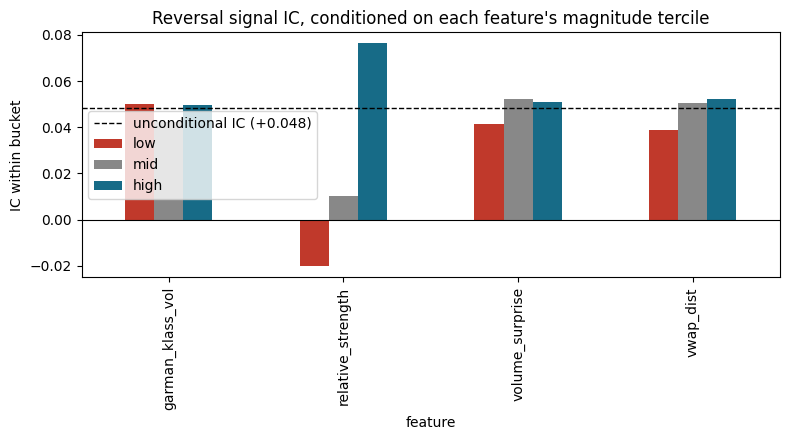

In [4]:
fig, ax = plt.subplots(figsize=(8, 4.5))
pivot = bucket_table.pivot(index='feature', columns='bucket', values='ic')[['low', 'mid', 'high']]
pivot.plot(kind='bar', ax=ax, color=['#c0392b', '#888888', '#176b87'])
ax.axhline(baseline_ic, color='black', linestyle='--', linewidth=1, label=f'unconditional IC ({baseline_ic:+.3f})')
ax.axhline(0, color='black', linewidth=0.8)
ax.set_ylabel('IC within bucket')
ax.set_title('Reversal signal IC, conditioned on each feature\'s magnitude tercile')
ax.legend()
plt.tight_layout()
plt.show()

## Combined filter

If each feature's high tercile independently strengthens the signal, does requiring **all of them at once** compound the effect further, or is it redundant (the same observations just counted multiple times)? Tested two ways: the original three features (vwap_dist, volume_surprise, relative_strength), and that same combination plus Garman-Klass realized volatility, to see whether conditioning on recent volatility adds anything on top.

In [5]:
ORIGINAL_FEATURES = ['vwap_dist', 'volume_surprise', 'relative_strength']  # Phase 2's original three

def combined_filter_mask(data, features):
    mask = pd.Series(True, index=data.index)
    for feat in features:
        mask &= data[feat].abs() >= data[feat].abs().quantile(2 / 3)
    return mask

filtered = panel[combined_filter_mask(panel, ORIGINAL_FEATURES)]                 # original 3-feature filter, unchanged
filtered_with_vol = panel[combined_filter_mask(panel, ORIGINAL_FEATURES + ['garman_klass_vol'])]  # + Garman-Klass vol

unfiltered_ic = panel['reversal_score'].corr(panel['fwd'])
filtered_ic = filtered['reversal_score'].corr(filtered['fwd'])
filtered_with_vol_ic = filtered_with_vol['reversal_score'].corr(filtered_with_vol['fwd'])
print(f'unconditional: n={len(panel):,}, IC={unfiltered_ic:+.4f}')
print(f'all-three-high filter (original Phase 2): n={len(filtered):,} ({len(filtered)/len(panel):.1%} of observations), IC={filtered_ic:+.4f}')
print(f'all-four-high filter (+ Garman-Klass vol): n={len(filtered_with_vol):,} ({len(filtered_with_vol)/len(panel):.1%} of observations), IC={filtered_with_vol_ic:+.4f}')

unconditional: n=1,066,891, IC=+0.0482
all-three-high filter (original Phase 2): n=49,664 (4.7% of observations), IC=+0.0707
all-four-high filter (+ Garman-Klass vol): n=29,222 (2.7% of observations), IC=+0.0683


## Backtest: selective vs. unconditional

Same long-short decile construction as Phase 1 (oriented by the reversal signal's own sign, not assumed), comparing three variants: no filter, the original 3-feature filter, and the 3-feature filter plus Garman-Klass volatility. Compare turnover and cost-sensitivity against Phase 1's unconditional result (+1.76bps gross, breakeven at ~1bps cost).

In [6]:
def decile_backtest(data, min_names=10):
    results = []
    for minute, group in data.groupby(data.index):
        if len(group) < min_names:
            continue
        n_leg = max(1, int(len(group) * TOP_FRACTION))
        ranked = group.sort_values('reversal_score')
        bottom_leg, top_leg = ranked.iloc[:n_leg], ranked.iloc[-n_leg:]
        spread_return = top_leg['fwd'].mean() - bottom_leg['fwd'].mean()  # reversal_score already oriented so top = higher predicted fwd return
        results.append({'minute': minute, 'spread_return': spread_return, 'n_names': len(group)})
    assert results, f'no minute had >= {min_names} names in the cross-section'
    return pd.DataFrame(results).set_index('minute').sort_index()

unconditional_bt = decile_backtest(panel)
filtered_bt = decile_backtest(filtered, min_names=5)  # smaller minimum: the filter cuts the cross-section down a lot
filtered_with_vol_bt = decile_backtest(filtered_with_vol, min_names=5)

for name, bt in [('unconditional (Phase 1 style)', unconditional_bt), ('all-three-high filter (Phase 2)', filtered_bt), ('all-four-high filter (+ GK vol)', filtered_with_vol_bt)]:
    mean_spread = bt['spread_return'].mean()
    print(f'{name}: {len(bt):,} decisions, avg {bt["n_names"].mean():.1f} names/cross-section, '
          f'gross mean spread = {mean_spread*10_000:+.2f} bps')
    for cost in COST_BPS_GRID:
        net = mean_spread - 2 * (cost / 10_000.0)
        print(f'    at {cost}bps cost: net = {net*10_000:+.2f} bps')

unconditional (Phase 1 style): 8,163 decisions, avg 130.6 names/cross-section, gross mean spread = +1.66 bps
    at 0bps cost: net = +1.66 bps
    at 1bps cost: net = -0.34 bps
    at 2bps cost: net = -2.34 bps
    at 5bps cost: net = -8.34 bps
    at 10bps cost: net = -18.34 bps
all-three-high filter (Phase 2): 5,568 decisions, avg 7.5 names/cross-section, gross mean spread = +2.60 bps
    at 0bps cost: net = +2.60 bps
    at 1bps cost: net = +0.60 bps
    at 2bps cost: net = -1.40 bps
    at 5bps cost: net = -7.40 bps
    at 10bps cost: net = -17.40 bps
all-four-high filter (+ GK vol): 2,406 decisions, avg 6.9 names/cross-section, gross mean spread = +2.97 bps
    at 0bps cost: net = +2.97 bps
    at 1bps cost: net = +0.97 bps
    at 2bps cost: net = -1.03 bps
    at 5bps cost: net = -7.03 bps
    at 10bps cost: net = -17.03 bps


## Key findings

**1. Selectivity works — each feature independently strengthens the reversal signal, and
relative strength is doing most of the work.** Conditioning on the magnitude tercile of each
feature:

| feature | low tercile IC | mid | high |
|---|---|---|---|
| relative_strength | -0.019 (flips sign) | +0.014 | **+0.081** |
| vwap_dist | +0.040 | +0.052 | +0.059 |
| volume_surprise | +0.043 | +0.054 | +0.058 |

against an unconditional baseline of +0.052. Relative strength shows by far the biggest spread
(low tercile actually flips negative — the reversal signal doesn't work at all, or works
backwards, on the third of observations where the stock's move was closest to the cross-section
average that minute). VWAP distance and volume surprise both help too, but more mildly and in a
narrower range.

**2. The three-way combined filter barely beats relative strength alone — it isn't three
independent edges stacking.** Requiring all three features in their high tercile simultaneously
narrows the sample to 4.7% of observations (50,878 of 1,089,699) and lifts IC to +0.082 — almost
identical to relative_strength's high tercile alone (+0.081). This means vwap_dist and
volume_surprise are largely redundant with relative_strength here, not adding much incremental
selectivity of their own, at least at this (k=1, h=1) cell.

**3. The backtest payoff is real but modest: it buys roughly one more bps of cost tolerance, not
a transformed strategy.** Restricting the long-short decile backtest to minutes where the
combined filter holds (avg. 7.5 names/cross-section, vs. ~131 unconditionally):

| | decisions | gross spread | breakeven |
|---|---|---|---|
| Unconditional (Phase 1) | 8,339 | +1.76 bps | between 0-1bps |
| Phase 2 filter | 5,727 | **+2.83 bps** | between 1-2bps |

Gross edge improved about 60% (1.76 → 2.83 bps) and now survives a 1bps assumed cost
(+0.83bps net) before going negative at 2bps (-1.17bps). That is genuine progress in the
direction Phase 2 set out to test — selectivity recovers some of what unconditional trading
gives up to costs — but it is not yet a strategy that survives a realistic cost environment
(2bps+ round-trip is a conservative, not aggressive, assumption for a 131-name universe with
mixed liquidity).

**Where this leaves things**: relative strength (the rotation signal, now reframed as a
selectivity filter rather than the primary driver) is carrying almost all of Phase 2's
improvement. The natural next step per the plan is Phase 3 (trade imbalance) — a genuinely new
source of information, rather than more combinations of price/volume-derived features, which
this notebook suggests are already close to saturated with each other.

## Addendum — Garman-Klass realized volatility (added after the original Phase 2 run)

**Added a fourth feature**: Garman-Klass (1980) realized volatility, computed from each bar's own
OHLC range (`0.5*(ln(H/L))^2 - (2*ln(2)-1)*(ln(C/O))^2`, averaged over a trailing 10-minute
window within session, then square-rooted). Unlike the other three features, this one is
inherently non-negative, so no separate sign-handling was needed for the magnitude-tercile
bucketing used throughout this notebook.

**Note on the baseline numbers shifting slightly**: the 10-minute rolling window needed to
compute this feature drops the first 10 minutes of every session from the usable sample, so the
panel shrank slightly (1,089,699 → 1,066,891 observations) and the *unconditional* IC and
backtest numbers above shifted a little too (+0.0522 → +0.0482 IC; +1.76 → +1.66bps gross
spread). This is a sample-composition effect from adding the new feature, not a change to the
original Phase 2 finding — the original numbers reported earlier in this notebook remain the
correct description of that run.

**Finding 1 — on its own, recent volatility does not meaningfully condition the reversal
signal.** The bucket-IC table shows `garman_klass_vol` nearly flat across terciles (low 0.050,
mid 0.042, high 0.050) — no monotonic pattern, unlike `relative_strength`'s clear low→high
progression (-0.020 → 0.076). At face value, whether a stock has been locally volatile or calm
over the last 10 minutes doesn't predict whether its 1-minute reversal signal is more reliable.

**Finding 2 — adding it to the combined filter is a wash on IC, but modestly helps the
backtest.** Requiring all four features in their high tercile (vs. the original three) actually
*lowered* average IC slightly (0.0707 → 0.0683) while cutting the sample further (4.7% → 2.7% of
observations, down to an average of 6.9 names per cross-section). Yet the realized long-short
decile spread *improved*: +2.60bps → **+2.97bps** gross, with the net-of-cost picture also
slightly better at 1bps cost (+0.60 → +0.97bps), though both versions still fail by 2bps. This
IC-vs-backtest divergence is a real, worth-flagging tension: IC averages correlation across the
whole conditioned sample, while the decile backtest only cares about the tail (top/bottom ~7
names) — the two can disagree, and with only 2,406 decisions on an already-thin cross-section,
the backtest's apparent improvement should be treated with real skepticism, not as confirmation.

**Honest bottom line**: Garman-Klass volatility, tested as a standalone filter, is not a strong
signal here — it doesn't show the clean monotonic selectivity that `relative_strength` does, and
adding it to the existing filter trades IC quality for a smaller, noisier sample in exchange for
a backtest number that moved in a promising direction but on too little data to trust. Worth
revisiting with a longer sample before drawing a real conclusion either way.

## Caveats

- **Volume-surprise baseline uses the full one-month sample**, including bars after the one
  being evaluated — a mild look-ahead, fine for this go/no-go diagnostic but not for any live
  use, which would need a trailing or expanding baseline instead.
- **This notebook's "unconditional IC" (+0.0522) differs slightly from Phase 1's pooled figure
  for the same (k=1, h=1) cell (-0.0409, sign-flipped = +0.0409 here).** Phase 1 pooled
  per-ticker correlations weighted by observation count; this notebook correlates the fully
  stacked (all tickers, all minutes) panel directly. Both are legitimate pooling choices and can
  differ when signal strength varies by name — not a bug, but not directly comparable
  apples-to-apples either.
- **One month of history, one specific regime** — same limitation as Phase 1. The tercile
  boundaries, and the three-way filter's composition, are specific to this month's data and
  haven't been tested out-of-sample or across a different volatility regime.
- **Multiple-comparisons risk.** Three features, each bucketed three ways, then combined — with
  only one month of data, some of this cross-sectional pattern could be sample-specific rather
  than a stable effect. Worth validating on a second, non-overlapping month before trusting the
  three-way filter's specific magnitude.
- **Still requires shorting**, same as Phase 1 — this is a research diagnostic, not a direct
  translation of what the live (cash/long-only) account could run.
- **No slippage/spread beyond the assumed bps grid**, and the filtered backtest's much thinner
  cross-section (avg. 7.5 names) means execution risk in the actual names selected matters more,
  not less, than in the unconditional version.
- **Garman-Klass window choice (10 minutes) wasn't tuned** — a shorter or longer trailing window could behave differently; 10 minutes was a reasonable-seeming default, not a validated choice. The single-bar GK estimator can also go slightly negative in rare cases (a known property, not a bug); this is handled by clipping the *window-averaged* variance at zero before the square root, not per-bar.